# CSET485 – AI and Society | Assignment 1
## Adult Census Income: model comparison, stress tests, and fairness analysis

**Student:** Amit Tiwari  
**Enrollment / roll number:** S24CSEU0627  
**Random state:** `627`  
**Train/test split:** 70% / 30%, stratified

### Reproducibility checklist
- Run **Kernel → Restart Kernel and Run All Cells** before submission.
- The data-loading cell downloads files from UCI, so internet access is required for a fresh run.
- The IQR outlier analysis is descriptive. It does not automatically remove observations.
- Saved outputs are historical notebook outputs; they are not proof of a fresh clean-kernel execution.

### Notebook roadmap
1. Load and clean data; 2. split and preprocess; 3. compare OLS and logistic regression; 4. examine subgroup coefficients; 5. test omitted-variable sensitivity; 6. inspect confident errors; 7. sweep fairness thresholds.


## 1. Imports and experiment settings

The random seed is 627, matching the last three digits of enrollment S24CSEU0627.

In [1]:
# If needed, install dependencies in a separate notebook cell:
# %pip install pandas numpy scikit-learn statsmodels matplotlib seaborn requests

import io
import warnings
import requests
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels.formula.api as smf

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.metrics import (
    confusion_matrix, accuracy_score, precision_score, recall_score,
    f1_score, roc_auc_score, classification_report
)
from IPython.display import display

warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", 100)
pd.set_option("display.width", 160)

# IMPORTANT: replace with the last 3 digits of your roll number.
RANDOM_SEED = 627  # last three digits of roll number
TEST_SIZE = 0.30

assert isinstance(RANDOM_SEED, int) and 0 <= RANDOM_SEED <= 999, "Seed must be the last three digits (0–999)."

## 2. Load and clean the Adult dataset

The original UCI training and test files are combined; the analysis uses the binary target income_binary.

In [2]:
DATA_URL = "https://archive.ics.uci.edu/ml/machine-learning-databases/adult/"
COLUMNS = [
    "age", "workclass", "fnlwgt", "education", "education_num",
    "marital_status", "occupation", "relationship", "race", "sex",
    "capital_gain", "capital_loss", "hours_per_week", "native_country", "income"
]

def download_text(url):
    response = requests.get(url, timeout=60)
    response.raise_for_status()
    return response.text

adult_train_text = download_text(DATA_URL + "adult.data")
adult_test_text = download_text(DATA_URL + "adult.test")

# adult.test has a comment/header line and labels ending in periods.
train_df = pd.read_csv(
    io.StringIO(adult_train_text), header=None, names=COLUMNS,
    na_values="?", skipinitialspace=True
)
test_df = pd.read_csv(
    io.StringIO(adult_test_text), header=None, names=COLUMNS,
    na_values="?", skipinitialspace=True, comment="|", skiprows=1
)

df = pd.concat([train_df, test_df], ignore_index=True)
for col in df.select_dtypes(include="object").columns:
    df[col] = df[col].str.strip()
df["income"] = df["income"].str.replace(".", "", regex=False).str.strip()
df["income_binary"] = (df["income"] == ">50K").astype(int)

print("Dataset shape:", df.shape)
print("\nIncome counts:")
display(df["income"].value_counts(dropna=False).to_frame("count"))
print("\nFirst rows:")
display(df.head())
print("\nMissing values by column:")
display(df.isna().sum().sort_values(ascending=False).to_frame("missing_count"))

Dataset shape: (48842, 16)

Income counts:


,count
income,
<=50K,37155
>50K,11687



First rows:


,age,workclass,fnlwgt,education,education_num,marital_status,occupation,relationship,race,sex,capital_gain,capital_loss,hours_per_week,native_country,income,income_binary
0,39,State-gov,77516,Bachelors,13,Never-married,Adm-clerical,Not-in-family,White,Male,2174,0,40,United-States,<=50K,0
1,50,Self-emp-not-inc,83311,Bachelors,13,Married-civ-spouse,Exec-managerial,Husband,White,Male,0,0,13,United-States,<=50K,0
2,38,Private,215646,HS-grad,9,Divorced,Handlers-cleaners,Not-in-family,White,Male,0,0,40,United-States,<=50K,0
3,53,Private,234721,11th,7,Married-civ-spouse,Handlers-cleaners,Husband,Black,Male,0,0,40,United-States,<=50K,0
4,28,Private,338409,Bachelors,13,Married-civ-spouse,Prof-specialty,Wife,Black,Female,0,0,40,Cuba,<=50K,0



Missing values by column:


,missing_count
occupation,2809
workclass,2799
native_country,857
fnlwgt,0
education,0
education_num,0
marital_status,0
age,0
relationship,0
race,0


## 3. Split, preprocess, and inspect outliers

The split is stratified 70:30. Imputation, scaling, and one-hot encoding are fitted within a pipeline on training data. IQR outlier counts are diagnostic only; observations are not automatically deleted.

In [3]:
numeric_cols = ["age", "fnlwgt", "education_num", "capital_gain", "capital_loss", "hours_per_week"]
categorical_cols = [
    "workclass", "marital_status", "occupation", "relationship",
    "race", "sex", "native_country"
]
feature_cols = numeric_cols + categorical_cols
target_col = "income_binary"

# Numeric distribution and IQR-based outlier counts (diagnostic only)
display(df[numeric_cols].describe().T)
outlier_rows = []
for col in numeric_cols:
    q1, q3 = df[col].quantile([0.25, 0.75])
    iqr = q3 - q1
    low, high = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    count = ((df[col] < low) | (df[col] > high)).sum()
    outlier_rows.append({"feature": col, "IQR_lower": low, "IQR_upper": high,
                         "outlier_count": int(count), "outlier_pct": 100 * count / len(df)})
display(pd.DataFrame(outlier_rows))

X = df[feature_cols].copy()
y = df[target_col].copy()
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=TEST_SIZE, random_state=RANDOM_SEED, stratify=y
)
print("Train rows:", len(X_train), "| Test rows:", len(X_test))
print("Train positive rate:", round(y_train.mean(), 4), "| Test positive rate:", round(y_test.mean(), 4))

numeric_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])
categorical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore"))
])
preprocessor = ColumnTransformer(transformers=[
    ("num", numeric_transformer, numeric_cols),
    ("cat", categorical_transformer, categorical_cols)
])

,count,mean,std,min,25%,50%,75%,max
age,48842.0,38.643585,13.710510,17.0,28.0,37.0,48.0,90.0
fnlwgt,48842.0,189664.134597,105604.025423,12285.0,117550.5,178144.5,237642.0,1490400.0
education_num,48842.0,10.078089,2.570973,1.0,9.0,10.0,12.0,16.0
capital_gain,48842.0,1079.067626,7452.019058,0.0,0.0,0.0,0.0,99999.0
capital_loss,48842.0,87.502314,403.004552,0.0,0.0,0.0,0.0,4356.0
hours_per_week,48842.0,40.422382,12.391444,1.0,40.0,40.0,45.0,99.0


,feature,IQR_lower,IQR_upper,outlier_count,outlier_pct
0,age,-2.00,78.00,216,0.442242
1,fnlwgt,-62586.75,417779.25,1453,2.974899
2,education_num,4.50,16.50,1794,3.673068
3,capital_gain,0.00,0.00,4035,8.261332
4,capital_loss,0.00,0.00,2282,4.672208
5,hours_per_week,32.50,52.50,13496,27.631956


Train rows: 34189 | Test rows: 14653
Train positive rate: 0.2393 | Test positive rate: 0.2393


## 4. Fit OLS and logistic regression; compare decisions

OLS uses the median of its test predictions; logistic regression uses a fixed probability cutoff of 0.5. These thresholds are not equivalent.

In [4]:
ols_model = Pipeline(steps=[
    ("preprocess", preprocessor),
    ("model", LinearRegression())
])
logit_model = Pipeline(steps=[
    ("preprocess", preprocessor),
    ("model", LogisticRegression(max_iter=2000, solver="liblinear", random_state=RANDOM_SEED))
])

ols_model.fit(X_train, y_train)
logit_model.fit(X_train, y_train)

ols_pred = ols_model.predict(X_test)
logit_prob = logit_model.predict_proba(X_test)[:, 1]
ols_median = float(np.median(ols_pred))
ols_class = (ols_pred >= ols_median).astype(int)
logit_class = (logit_prob >= 0.5).astype(int)

comparison_cm = confusion_matrix(ols_class, logit_class, labels=[0, 1])
mismatch = (ols_class != logit_class)
mismatch_count = int(mismatch.sum())
mismatch_pct = 100 * mismatch.mean()

print(f"Median OLS prediction on test set: {ols_median:.6f}")
print(f"OLS prediction min/max: {ols_pred.min():.4f} / {ols_pred.max():.4f}")
print(f"Logistic probability min/max: {logit_prob.min():.4f} / {logit_prob.max():.4f}")
print("\nAgreement/disagreement confusion matrix (rows = OLS class, columns = logistic class):")
display(pd.DataFrame(comparison_cm,
                     index=["OLS low (0)", "OLS high (1)"],
                     columns=["Logistic low (0)", "Logistic high (1)"]))
print(f"Mismatched cases: {mismatch_count:,} / {len(y_test):,} = {mismatch_pct:.2f}%")

print("\nAdditional test-set performance against actual income labels (for context):")
print("OLS thresholded accuracy:", round(accuracy_score(y_test, ols_class), 4))
print("Logistic accuracy:", round(accuracy_score(y_test, logit_class), 4))
print("Logistic precision:", round(precision_score(y_test, logit_class, zero_division=0), 4))
print("Logistic recall:", round(recall_score(y_test, logit_class, zero_division=0), 4))
print("Logistic F1:", round(f1_score(y_test, logit_class, zero_division=0), 4))
print("Logistic ROC-AUC:", round(roc_auc_score(y_test, logit_prob), 4))

Median OLS prediction on test set: 0.222977
OLS prediction min/max: -0.4125 / 1.7520
Logistic probability min/max: 0.0000 / 1.0000

Agreement/disagreement confusion matrix (rows = OLS class, columns = logistic class):


,Logistic low (0),Logistic high (1)
OLS low (0),7313,13
OLS high (1),4369,2958


Mismatched cases: 4,382 / 14,653 = 29.91%

Additional test-set performance against actual income labels (for context):
OLS thresholded accuracy: 0.7126
Logistic accuracy: 0.8543
Logistic precision: 0.7307
Logistic recall: 0.6192
Logistic F1: 0.6704
Logistic ROC-AUC: 0.9057


## 5. Subgroup coefficient analysis

The assignment asks for a reversal if one exists. If coefficient signs do not reverse, report the observed magnitude difference without claiming a confirmed Simpson’s paradox.

In [5]:
# Compact inferential formula; categorical predictors are handled by C(...)
infer_formula = (
    "income_binary ~ age + education_num + hours_per_week + capital_gain + capital_loss "
    "+ C(sex) + C(race) + C(marital_status) + C(relationship)"
)

def fit_logit_formula(data, formula=infer_formula):
    model = smf.logit(formula=formula, data=data).fit(disp=False, maxiter=200)
    return model

infer_df = df.copy()
for col in ["age", "education_num", "hours_per_week", "capital_gain", "capital_loss", "income_binary"]:
    infer_df[col] = pd.to_numeric(infer_df[col], errors="coerce")
infer_df = infer_df.dropna(subset=["income_binary", "age", "education_num", "hours_per_week",
                                   "capital_gain", "capital_loss", "sex", "race",
                                   "marital_status", "relationship"])

full_subgroup_model = fit_logit_formula(infer_df)
# Sex is removed from subgroup formulas because it is constant within each subgroup.
subgroup_formula = (
    "income_binary ~ age + education_num + hours_per_week + capital_gain + capital_loss "
    "+ C(race) + C(marital_status) + C(relationship)"
)
female_model = fit_logit_formula(infer_df[infer_df["sex"] == "Female"], subgroup_formula)
male_model = fit_logit_formula(infer_df[infer_df["sex"] == "Male"], subgroup_formula)

def coef_ci(model, term):
    ci = model.conf_int().loc[term]
    return {"coefficient": model.params[term], "CI_lower": ci.iloc[0],
            "CI_upper": ci.iloc[1], "p_value": model.pvalues[term]}

subgroup_rows = []
for label, model in [("Full dataset", full_subgroup_model),
                     ("Female subgroup", female_model), ("Male subgroup", male_model)]:
    result = coef_ci(model, "age")
    subgroup_rows.append({"model": label, **result})
subgroup_table = pd.DataFrame(subgroup_rows)
display(subgroup_table.round(5))

print("Interpretation guide: the age coefficient is the change in log-odds of income >$50K per one-year increase in age, conditional on included predictors.")
print("Check coefficient signs and confidence intervals before claiming a reversal. A non-reversal is still reportable as a subgroup difference.")

,model,coefficient,CI_lower,CI_upper,p_value
0,Full dataset,0.02275,0.02033,0.02517,0.0
1,Female subgroup,0.02895,0.02287,0.03504,0.0
2,Male subgroup,0.02139,0.01876,0.02403,0.0


Interpretation guide: the age coefficient is the change in log-odds of income >$50K per one-year increase in age, conditional on included predictors.
Check coefficient signs and confidence intervals before claiming a reversal. A non-reversal is still reportable as a subgroup difference.


### Additional diagnostic: formal sex-by-age interaction test

This likelihood-ratio test compares the main-effects model with a model that adds an age × sex interaction. Interpret the p-value only after running the notebook from a clean kernel; a significant interaction supports different age slopes, but is not proof of causation or Simpson’s paradox.

In [ ]:
# Formal interaction test for whether the age coefficient differs by sex.
# This cell is intended to be executed during a clean Run All.
interaction_formula = (
    "income_binary ~ age * C(sex) + education_num + hours_per_week + capital_gain + capital_loss "
    "+ C(race) + C(marital_status) + C(relationship)"
)
main_effect_formula = (
    "income_binary ~ age + C(sex) + education_num + hours_per_week + capital_gain + capital_loss "
    "+ C(race) + C(marital_status) + C(relationship)"
)
main_effect_fit = fit_logit_formula(infer_df, main_effect_formula)
interaction_fit = fit_logit_formula(infer_df, interaction_formula)
lr_stat = 2 * (interaction_fit.llf - main_effect_fit.llf)
lr_df = int(interaction_fit.df_model - main_effect_fit.df_model)
lr_pvalue = float(__import__("scipy").stats.chi2.sf(lr_stat, lr_df))
print(f"Likelihood-ratio test for age × sex interaction: chi2({lr_df}) = {lr_stat:.4f}, p = {lr_pvalue:.6g}")
print("Interaction coefficient(s):")
display(interaction_fit.params.filter(like="age:C(sex)").to_frame("coefficient"))


## 6. Omitted-variable sensitivity analysis

The reduced model omits education_num. Coefficient changes demonstrate model-specification sensitivity, not causality by themselves.

In [6]:
reduced_formula = (
    "income_binary ~ age + hours_per_week + capital_gain + capital_loss "
    "+ C(sex) + C(race) + C(marital_status) + C(relationship)"
)
reduced_model = fit_logit_formula(infer_df, reduced_formula)

compare_terms = ["age", "hours_per_week", "capital_gain", "capital_loss"]
ovb_rows = []
for term in compare_terms:
    full_c = float(full_subgroup_model.params[term])
    reduced_c = float(reduced_model.params[term])
    delta = reduced_c - full_c
    denom = abs(full_c)
    ovb_rows.append({
        "predictor": term,
        "full_coefficient": full_c,
        "reduced_coefficient": reduced_c,
        "change_reduced_minus_full": delta,
        "signed_pct_change": (100 * delta / denom) if denom > 1e-12 else np.nan,
        "absolute_pct_change": (100 * abs(delta) / denom) if denom > 1e-12 else np.nan
    })
ovb_table = pd.DataFrame(ovb_rows)
display(ovb_table.round(5))
largest_shift = ovb_table.loc[ovb_table["absolute_pct_change"].idxmax()]
print("Largest absolute percentage shift among the four reported predictors:",
      largest_shift["predictor"], "=", round(largest_shift["absolute_pct_change"], 2), "%")

,predictor,full_coefficient,reduced_coefficient,change_reduced_minus_full,signed_pct_change,absolute_pct_change
0,age,0.02275,0.01922,-0.00353,-15.52075,15.52075
1,hours_per_week,0.03022,0.03246,0.00224,7.41724,7.41724
2,capital_gain,0.00032,0.00032,0.00001,2.05720,2.05720
3,capital_loss,0.00066,0.00073,0.00007,11.04572,11.04572


Largest absolute percentage shift among the four reported predictors: age = 15.52 %


## 7. Confident incorrect predictions

The notebook counts all high-confidence incorrect predictions, then reproducibly samples up to 50 for demographic comparison.

In [7]:
test_results = X_test.copy()
test_results["actual"] = y_test.to_numpy()
test_results["probability"] = logit_prob
test_results["predicted"] = logit_class
test_results["error_type"] = np.select(
    [
        (test_results["probability"] >= 0.75) & (test_results["actual"] == 0),
        (test_results["probability"] <= 0.25) & (test_results["actual"] == 1)
    ],
    ["High-confidence false positive", "High-confidence false negative"],
    default="Not selected"
)
adversarial = test_results[test_results["error_type"] != "Not selected"].copy()
available_count = len(adversarial)
if available_count > 50:
    adversarial = adversarial.sample(n=50, random_state=RANDOM_SEED)
print("High-confidence wrong predictions found before sampling:", available_count)
print("Rows in analyzed adversarial subset:", len(adversarial))
print("Percentage of full test set:", round(100 * available_count / len(test_results), 3), "%")
if len(adversarial):
    print("\nError type counts:")
    display(adversarial["error_type"].value_counts().to_frame("count"))
    print("\nAge distribution: adversarial subset vs full test set")
    display(pd.DataFrame({
        "adversarial_subset": adversarial["age"].describe(),
        "full_test_set": test_results["age"].describe()
    }).round(3))
    for col in ["sex", "race", "marital_status", "relationship"]:
        print(f"\n{col}: adversarial subset (%), compared with full test set (%)")
        adv_pct = adversarial[col].value_counts(normalize=True, dropna=False).mul(100).rename("adversarial_pct")
        test_pct = test_results[col].value_counts(normalize=True, dropna=False).mul(100).rename("test_pct")
        display(pd.concat([adv_pct, test_pct], axis=1).fillna(0).round(2).sort_values("adversarial_pct", ascending=False).head(12))
else:
    print("No cases meet the specified confidence/error criteria on this split. Report zero and explain that the requested subset could not be constructed from this model/split; do not fabricate rows.")

High-confidence wrong predictions found before sampling: 725
Rows in analyzed adversarial subset: 50
Percentage of full test set: 4.948 %

Error type counts:


,count
error_type,
High-confidence false negative,39
High-confidence false positive,11



Age distribution: adversarial subset vs full test set


,adversarial_subset,full_test_set
count,50.000,14653.000
mean,46.080,38.571
std,12.688,13.565
min,24.000,17.000
25%,37.000,28.000
50%,43.000,37.000
75%,52.750,48.000
max,90.000,90.000



sex: adversarial subset (%), compared with full test set (%)


...

,adversarial_pct,test_pct
race,,
White,88.0,86.20
Black,12.0,9.23
Asian-Pac-Islander,0.0,2.93
Other,0.0,0.83
Amer-Indian-Eskimo,0.0,0.82



marital_status: adversarial subset (%), compared with full test set (%)


,adversarial_pct,test_pct
marital_status,,
Married-civ-spouse,58.0,46.04
Never-married,28.0,32.53
Divorced,12.0,13.92
Widowed,2.0,3.04
Separated,0.0,3.20
Married-spouse-absent,0.0,1.21
Married-AF-spouse,0.0,0.05



relationship: adversarial subset (%), compared with full test set (%)


,adversarial_pct,test_pct
relationship,,
Husband,52.0,40.65
Not-in-family,32.0,25.89
Unmarried,8.0,10.47
Own-child,4.0,15.27
Wife,4.0,4.59
Other-relative,0.0,3.14


## 8. Fairness threshold sweep

The groups are Female (A) and Male (B). EO follows the assignment-defined minimum of TPR_A/TPR_B and FPR_A/FPR_B; the component rates should also be inspected separately.

,threshold,DP_ratio,EO_ratio,PP_ratio,Female_selection_rate,Male_selection_rate,Female_TPR,Male_TPR,Female_FPR,Male_FPR,Female_PPV,Male_PPV,accuracy
0,0.05,0.4708,0.4480,0.6784,0.3426,0.7277,0.930,0.9884,0.2746,0.6129,0.2816,0.4152,0.6287
1,0.15,0.3042,0.2561,0.9130,0.1766,0.5805,0.776,0.9484,0.1072,0.4186,0.4559,0.4994,0.7551
2,0.25,0.2897,0.2414,0.9432,0.1347,0.4649,0.700,0.8696,0.0692,0.2868,0.5393,0.5717,0.8090
3,0.35,0.2937,0.2533,0.9370,0.1079,0.3674,0.626,0.7721,0.0479,0.1892,0.6019,0.6424,0.8382
4,0.45,0.2877,0.2431,0.9620,0.0845,0.2936,0.552,0.6770,0.0303,0.1248,0.6781,0.7049,0.8514
5,0.55,0.2648,0.2247,0.9694,0.0631,0.2383,0.446,0.5898,0.0188,0.0835,0.7336,0.7567,0.8525
6,0.65,0.2635,0.2217,0.9802,0.0471,0.1788,0.362,0.4757,0.0107,0.0480,0.7974,0.8134,0.8452
7,0.75,0.2731,0.2501,0.9720,0.0330,0.1208,0.268,0.3426,0.0058,0.0231,0.8428,0.8670,0.8277
8,0.85,0.2847,0.3215,0.9594,0.0210,0.0736,0.178,0.2212,0.0028,0.0086,0.8812,0.9185,0.8073
9,0.95,0.2728,0.2258,0.9987,0.0104,0.0380,0.098,0.1221,0.0002,0.0010,0.9800,0.9813,0.7886


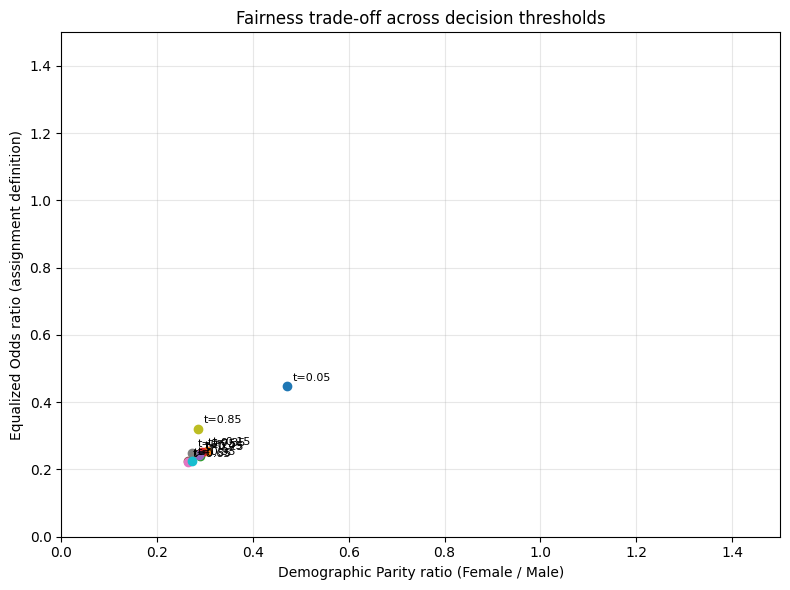

Reminder: DP, EO, and PP ratios all equal to 1 would indicate parity under these definitions, but they may conflict across thresholds.
Choose a threshold only after considering the application context and the harms of false positives and false negatives.


In [8]:
def safe_ratio(a, b):
    if pd.isna(a) or pd.isna(b) or abs(b) < 1e-12:
        return np.nan
    return a / b

def group_rates(y_true, y_pred):
    y_true = np.asarray(y_true).astype(int)
    y_pred = np.asarray(y_pred).astype(int)
    pos = (y_pred == 1)
    actual_pos = (y_true == 1)
    actual_neg = (y_true == 0)
    tpr = ((pos) & actual_pos).sum() / actual_pos.sum() if actual_pos.sum() else np.nan
    fpr = ((pos) & actual_neg).sum() / actual_neg.sum() if actual_neg.sum() else np.nan
    dp = pos.mean() if len(pos) else np.nan
    pp = (y_true[pos] == 1).mean() if pos.sum() else np.nan
    return {"DP_rate": dp, "TPR": tpr, "FPR": fpr, "PPV": pp}

fairness_rows = []
sex_test = X_test["sex"].reset_index(drop=True)
y_test_arr = y_test.reset_index(drop=True).to_numpy()
for threshold in np.round(np.arange(0.05, 0.951, 0.1), 2):
    pred = (logit_prob >= threshold).astype(int)
    group_a = sex_test.eq("Female").to_numpy()
    group_b = sex_test.eq("Male").to_numpy()
    rates_a = group_rates(y_test_arr[group_a], pred[group_a])
    rates_b = group_rates(y_test_arr[group_b], pred[group_b])
    dp_ratio = safe_ratio(rates_a["DP_rate"], rates_b["DP_rate"])
    tpr_ratio = safe_ratio(rates_a["TPR"], rates_b["TPR"])
    fpr_ratio = safe_ratio(rates_a["FPR"], rates_b["FPR"])
    eo_ratio = np.nanmin([tpr_ratio, fpr_ratio]) if not (np.isnan(tpr_ratio) and np.isnan(fpr_ratio)) else np.nan
    pp_ratio = safe_ratio(rates_a["PPV"], rates_b["PPV"])
    fairness_rows.append({
        "threshold": threshold,
        "DP_ratio": dp_ratio,
        "EO_ratio": eo_ratio,
        "PP_ratio": pp_ratio,
        "Female_selection_rate": rates_a["DP_rate"],
        "Male_selection_rate": rates_b["DP_rate"],
        "Female_TPR": rates_a["TPR"], "Male_TPR": rates_b["TPR"],
        "Female_FPR": rates_a["FPR"], "Male_FPR": rates_b["FPR"],
        "Female_PPV": rates_a["PPV"], "Male_PPV": rates_b["PPV"],
        "accuracy": accuracy_score(y_test_arr, pred)
    })

fairness_table = pd.DataFrame(fairness_rows)
display(fairness_table.round(4))

plt.figure(figsize=(8, 6))
for _, row in fairness_table.iterrows():
    if pd.notna(row["DP_ratio"]) and pd.notna(row["EO_ratio"]):
        plt.scatter(row["DP_ratio"], row["EO_ratio"])
        plt.annotate(f't={row["threshold"]:.2f}', (row["DP_ratio"], row["EO_ratio"]),
                     xytext=(4, 4), textcoords="offset points", fontsize=8)
plt.xlim(0, 1.5)
plt.ylim(0, 1.5)
plt.xlabel("Demographic Parity ratio (Female / Male)")
plt.ylabel("Equalized Odds ratio (assignment definition)")
plt.title("Fairness trade-off across decision thresholds")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

print("Reminder: DP, EO, and PP ratios all equal to 1 would indicate parity under these definitions, but they may conflict across thresholds.")
print("Choose a threshold only after considering the application context and the harms of false positives and false negatives.")

## Interpretation and limitations

- The analysis is observational; regression coefficients are conditional associations, not causal effects.
- The saved subgroup results show positive age coefficients for the full, Female, and Male models. They do not establish a sign reversal.
- The formal age × sex interaction test above is an additional diagnostic; its result must be read from a fresh run, not assumed from the saved outputs.
- EO is calculated using the assignment's minimum-ratio definition. Always inspect the TPR and FPR ratios separately because a minimum can conceal which component drives the result.
- The threshold sweep is non-monotonic. Do not claim a DP gain causes an EO loss unless the observed values support that direction.
- This exercise does not validate the model for real-world eligibility, employment, credit, or other high-impact decisions.


In [ ]:
# Audit the observed sweep rather than assuming a DP/EO trade-off direction.
if "fairness_table" in globals():
    ft = fairness_table.dropna(subset=["DP_ratio", "EO_ratio"]).copy()
    pairs = []
    for _, before in ft.iterrows():
        for _, after in ft.iterrows():
            dp_improves = abs(float(after["DP_ratio"]) - 1) < abs(float(before["DP_ratio"]) - 1)
            eo_worsens = abs(float(after["EO_ratio"]) - 1) > abs(float(before["EO_ratio"]) - 1)
            if dp_improves and eo_worsens:
                pairs.append((before["threshold"], after["threshold"], before["DP_ratio"], after["DP_ratio"], before["EO_ratio"], after["EO_ratio"]))
    if pairs:
        print("Threshold pairs where DP moves closer to parity while EO moves farther from parity:")
        display(pd.DataFrame(pairs, columns=["from_t", "to_t", "DP_before", "DP_after", "EO_before", "EO_after"]))
    else:
        print("No tested pair simultaneously moves DP closer to 1 and EO farther from 1. Report the observed changes without inventing this trade-off.")
else:
    print("Run the fairness threshold-sweep cell first.")
